# <font color='red' size='6'>Inteligência Artificial</font>
### Visão Computacional: CNN, Redes pré-treinadas e Transfer Learning
#### Experimento II envolvendo CNN com PyTorch e o dataset fashion_mnist_dataset
##### Objetivo da Atividade: pesquisar como instalar o PyTorch, realizar a instalação, executar o código abaixo fazendo uso do modelo ResNet18, salvar o modelo gerado, carregar o modelo e fazer alguns testes com as imagens fornecidas.

#### Marcar com um X a turma a qual o grupo pertence.</br>

<b>Turma: ( &nbsp;&nbsp;&nbsp;&nbsp; )   7G</br> Turma: ( X ) 7N </b><p>
<table width="300" border="2">
    <tr>
        <td><b>Nome do Aluno</b> </td>
        <td><b>RA</b></td>
     </tr>  
   <tr>
       <td>Gabriel Ferreira </td>
       <td>10442043</td>
   </tr>
   <tr>
       <td>—</td>
       <td>—</td>
   </tr>
   <tr>
       <td>—</td>
       <td>—</td>
   </tr>
   <tr>
       <td>—</td>
       <td>—</td>
   </tr>
   <tr>
       <td>—</td>
       <td>—</td>
   </tr>
   <tr>
       <td>—</td>
       <td>—</td>
   </tr>
</table>

#### Dataset: fashion_mnist_dataset
<ol type="a">
    <li>Estrutura do Dataset:</li>
    <ul>
        <li>O Fashion MNIST possui 60.000 imagens de treinamento e 10.000 imagens de teste, com 10 classes distintas.</li>
<li>Cada imagem tem o tamanho de 28x28 pixels em escala de cinza (1 canal de cor).</li>
<li>O dataset está estruturado em dois arquivos principais:</li>
        <ul>
            <li>train_images: contém as 60.000 imagens de treinamento.</li>
<li>test_images: contém as 10.000 imagens de teste.</li>
<li>train_labels: rótulos (labels) das imagens de treinamento.</li>
<li>test_labels: rótulos das imagens de teste.</li>
        </ul>
        <li>Cada imagem é associada a um rótulo de classe, que varia de 0 a 9, representando diferentes tipos de roupas.</li>
    </ul>
    <li>Estrutura do Dataset:</li>
    <ul>
        <li>As classes representam diferentes categorias de roupas, conforme listado abaixo:</li>
        <ol type="1">
            <li>T-shirt/top (camiseta)</li>
            <li>Trouser (calça)</li>
            <li>Pullover (suéter)</li>
            <li>Dress (vestido)</li>
            <li>Coat (casaco)</li>
            <li>Sandal (sandália)</li>
            <li>Shirt (camisa)</li>
            <li>Sneaker (tênis)</li>
            <li>Bag (bolsa)</li>
            <li>Ankle boot (bota)</li>
        </ol>
    </ul>
    <li>Formato das Imagens:</li>
    <ul>
    <li>As imagens possuem 28x28 pixels, com valores de intensidade de pixel variando de 0 a 255 (escala de cinza).</li>
    <li>As imagens são redimensionadas para 28x28, o que facilita o processamento e a análise. Apesar de serem simples e de baixa resolução, elas são uma boa base para testar a capacidade de um modelo de redes neurais para aprender padrões visuais.</li>
     </ul>
    <li>Objetivo do Dataset:</li>
    <ul>
    <li>O objetivo principal do Fashion MNIST é a classificação de imagens, onde o modelo precisa identificar corretamente a classe de uma imagem de roupa.</li>
    <li>Pode ser utilizado para treinar modelos de Redes Neurais Convolucionais (CNNs) e outros modelos de aprendizado de máquina, como SVMs e Árvores de Decisão.</li>
     </ul>
    <li>Pré-processamento e Normalização:</li>
    <ul>
    <li>Para melhorar a eficiência do treinamento, é comum normalizar os valores dos pixels para o intervalo [0, 1], dividindo os valores dos pixels por 255.</li>
    <li>Além disso, o dataset pode ser dividido em subconjuntos de treinamento, validação e teste, para avaliar o desempenho de modelos em diferentes estágios.</li>
     </ul>
        <li>Carregamento do Dataset:</li>
    <ul>
    <li>O Fashion MNIST pode ser carregado diretamente de bibliotecas como TensorFlow, Keras, ou PyTorch. </li>
     </ul>
</ol>

#### Referência
<p>ZALANDO RESEARCH. Fashion MNIST: A novel image dataset for benchmarking machine learning algorithms. arXiv, 2017. Disponível em: https://arxiv.org/abs/1708.07747. Acesso em: 6 mai. 2026.</p>

**Execução individual:** Gabriel Ferreira, RA 10442043. Turma 07N. Para viabilizar o experimento local, foi usada uma amostra estratificada e reproduzível de 200 imagens por classe no treino e 50 por classe na validação e no teste. As amostras de teste são disjuntas do treino. Resultados não representam o desempenho no conjunto completo.


In [1]:
"""
Classificador de roupas reais com Transfer Learning (ResNet18) usando PyTorch.
Inclui treino, validação, teste, gráficos e matriz de confusão.

OBSERVAÇÃO: Faça mudanças no número de épocas e verifique o melhor resultado.
"""
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import os
torch.manual_seed(10442043)


In [2]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Dispositivo usado:", device)

Dispositivo usado: mps


In [3]:
BATCH_SIZE = 32
IMG_SIZE = 96
NUM_EPOCHS = 5

In [4]:
# Definir as transformações usadas no treinamento
mean = [0.485, 0.456, 0.406]  # Valores de média do ImageNet
std = [0.229, 0.224, 0.225]   # Valores de desvio padrão do ImageNet

In [5]:
transform = {
    'train': transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.Grayscale(num_output_channels=3), transforms.RandomHorizontalFlip(), transforms.ToTensor(), transforms.Normalize(mean, std)]),
    'val': transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.Grayscale(num_output_channels=3), transforms.ToTensor(), transforms.Normalize(mean, std)]),
    'test': transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.Grayscale(num_output_channels=3), transforms.ToTensor(), transforms.Normalize(mean, std)]),
}

In [6]:
from pathlib import Path
from zipfile import ZipFile
if not Path('fashion_mnist_amostra').exists():
    with ZipFile('dados_experimentos_cnn.zip') as archive:
        archive.extractall('.')
data_dir = 'fashion_mnist_amostra'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), transform[x]) for x in ['train', 'val', 'test']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=BATCH_SIZE, shuffle=(x == 'train'), num_workers=0) for x in ['train', 'val', 'test']}
class_names = image_datasets['train'].classes
num_classes = len(class_names)
print({x: len(image_datasets[x]) for x in image_datasets})

{'train': 2000, 'val': 500, 'test': 500}


In [7]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for param in model.parameters():
    param.requires_grad = False
model.fc = nn.Sequential(nn.Linear(model.fc.in_features, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, num_classes))
model = model.to(device)

In [8]:
# Função de perda e otimizador
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

In [9]:
# Função de treino e validação
def train_model(model, criterion, optimizer, num_epochs=10):
    train_loss_history = []
    val_loss_history = []
    train_acc_history = []
    val_acc_history = []

    for epoch in range(num_epochs):
        print(f"Época {epoch+1}/{num_epochs}")

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0
            total = 0

            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
                total += labels.size(0)

            epoch_loss = running_loss / total
            epoch_acc = running_corrects.item() / total

            if phase == 'train':
                train_loss_history.append(epoch_loss)
                train_acc_history.append(epoch_acc)
            else:
                val_loss_history.append(epoch_loss)
                val_acc_history.append(epoch_acc)

            print(f"{phase.capitalize()} - Loss: {epoch_loss:.4f}, Acc: {epoch_acc:.4f}")

    return train_loss_history, val_loss_history, train_acc_history, val_acc_history

In [10]:
# Treinamento
train_loss, val_loss, train_acc, val_acc = train_model(model, criterion, optimizer, NUM_EPOCHS)

Época 1/5


Train - Loss: 1.5205, Acc: 0.5115


Val - Loss: 0.8739, Acc: 0.7460
Época 2/5


Train - Loss: 0.8261, Acc: 0.7155


Val - Loss: 0.7015, Acc: 0.7600
Época 3/5


Train - Loss: 0.7310, Acc: 0.7555


Val - Loss: 0.6403, Acc: 0.7900
Época 4/5


Train - Loss: 0.6766, Acc: 0.7625


Val - Loss: 0.6529, Acc: 0.7660
Época 5/5


Train - Loss: 0.6087, Acc: 0.7935


Val - Loss: 0.5962, Acc: 0.8020


In [11]:
model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for inputs, labels in dataloaders['test']:
        outputs = model(inputs.to(device))
        y_true.extend(labels.numpy())
        y_pred.extend(outputs.argmax(dim=1).cpu().numpy())
print('Acurácia teste:', np.mean(np.array(y_true) == np.array(y_pred)))

Acurácia teste: 0.772


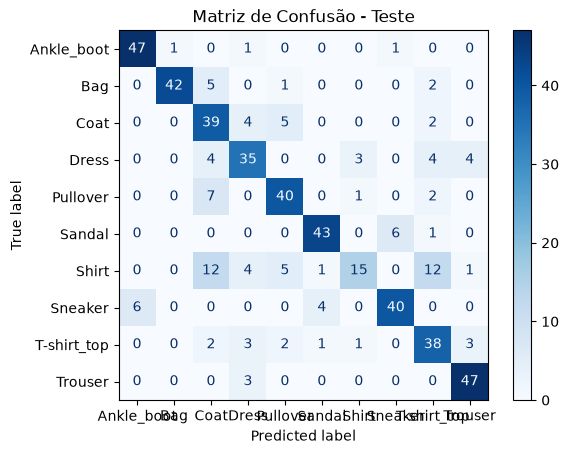

In [12]:
# Matriz de confusão
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues")
plt.title("Matriz de Confusão - Teste")
plt.show()

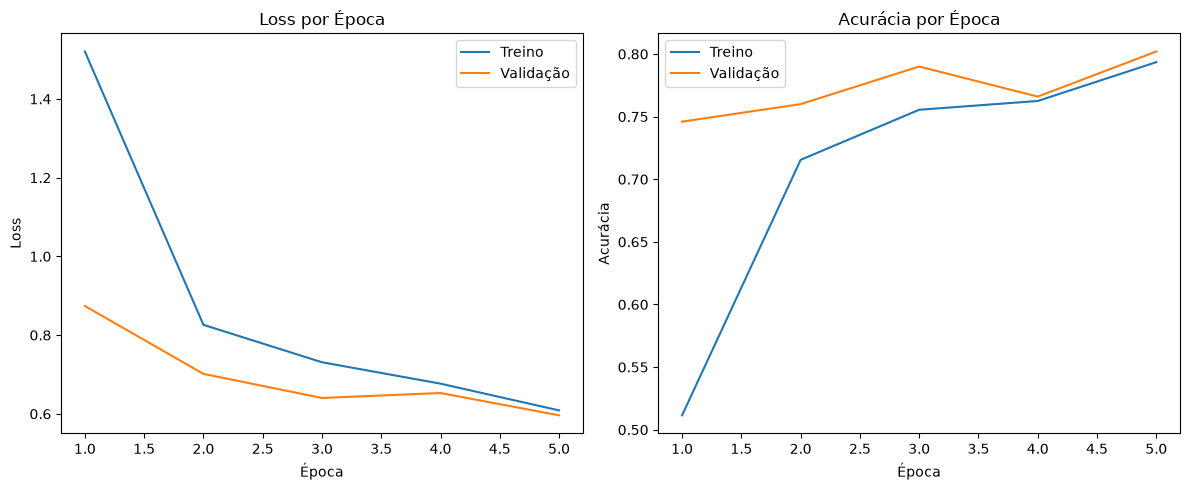

In [13]:
# Gráficos
epochs = range(1, NUM_EPOCHS + 1)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, label='Treino')
plt.plot(epochs, val_loss, label='Validação')
plt.title('Loss por Época')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, train_acc, label='Treino')
plt.plot(epochs, val_acc, label='Validação')
plt.title('Acurácia por Época')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.legend()

plt.tight_layout()
plt.show()

In [14]:
from PIL import Image # carregar a imagem

In [15]:
# Salvando o modelo treinado
torch.save(model.state_dict(), 'model_resnet18.pth')
print("Modelo salvo com sucesso!")

Modelo salvo com sucesso!


In [16]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [17]:
import sys
import os
from contextlib import redirect_stdout

# Garantir que o código redirecione toda a saída
with open(os.devnull, 'w') as fnull, redirect_stdout(fnull):
    # Carregar os pesos do modelo
    model.load_state_dict(torch.load('model_resnet18.pth', weights_only=True))

In [18]:
# Configurar o modelo para modo de avaliação (não imprime nada aqui)
with open(os.devnull, 'w') as fnull, redirect_stdout(fnull):
    model.eval()  # Não imprime nada aqui

In [19]:
# Carregando o modelo salvo e imprime os valores dos pesos e parametros da rede, se desejar
# basta tirar os comentarios a seguir
#  model.load_state_dict(torch.load('model_resnet18.pth', weights_only=True))
#  model.eval()

In [20]:
# Definir as mesmas transformações usadas no treinamento
mean = [0.485, 0.456, 0.406]  # Valores de média do ImageNet
std = [0.229, 0.224, 0.225]   # Valores de desvio padrão do ImageNet

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),  # Redimensionar a imagem
    transforms.Grayscale(num_output_channels=3),  # Converte para 3 canais (RGB)
    transforms.ToTensor(),  # Converter para tensor
    transforms.Normalize(mean, std)  # Normalizar com média e desvio padrão do ImageNet
])

In [21]:
def predict_image(image_path, model, transform, class_names):
    with Image.open(image_path) as original:
        image = transform(original).unsqueeze(0).to(device)
        plt.imshow(original)
        plt.title(Path(image_path).name)
        plt.axis('off')
        plt.show()
    with torch.no_grad():
        probabilities = torch.softmax(model(image), dim=1).squeeze().cpu().numpy()
    predicted = int(probabilities.argmax())
    return class_names[predicted], float(probabilities[predicted]), probabilities

In [22]:
from pathlib import Path
current_directory = Path.cwd()

In [23]:
# Três imagens externas de categorias conhecidas.

In [24]:
image_paths = [current_directory / name for name in ('imagemTesteSueter.jpg', 'imagemTesteCalca.jpg', 'imagemTesteTenis.jpg')]

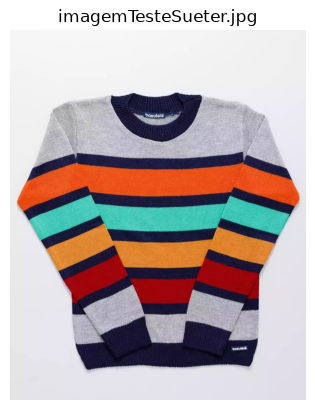

imagemTesteSueter.jpg: Pullover, confiança 0.4000


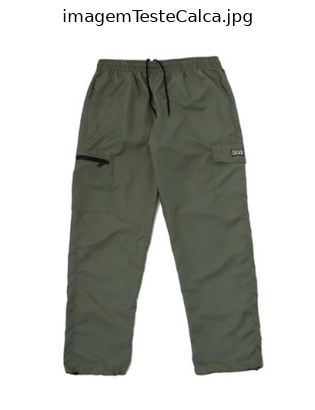

imagemTesteCalca.jpg: Shirt, confiança 0.2456


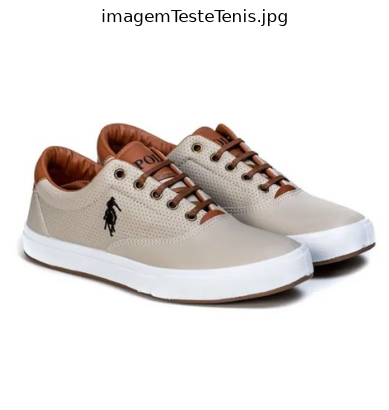

imagemTesteTenis.jpg: Bag, confiança 0.9808


In [25]:
external_results = []
for image_path in image_paths:
    predicted_class, confidence, probabilities = predict_image(image_path, model, transform, class_names)
    external_results.append((image_path.name, predicted_class, confidence))
    print(f'{image_path.name}: {predicted_class}, confiança {confidence:.4f}')

In [26]:
external_results

[('imagemTesteSueter.jpg', 'Pullover', 0.3999948501586914),
 ('imagemTesteCalca.jpg', 'Shirt', 0.24558258056640625),
 ('imagemTesteTenis.jpg', 'Bag', 0.9808175563812256)]

### <font size = '2'>prof. Dr. Ivan Carlos Alcântara de Oliveira</font> - <font color="blue" size = '2'>https://orcid.org/0000-0002-6020-7535.</font><br><font size = '2'> e-mail: ivan.oliveira@mackenzie.br</font>

In [27]:
import json
from pathlib import Path
results = {'model': 'ResNet18', 'epochs': NUM_EPOCHS, 'classes': class_names, 'train_loss': train_loss, 'val_loss': val_loss, 'train_acc': train_acc, 'val_acc': val_acc, 'test_accuracy': float(np.mean(np.array(y_true)==np.array(y_pred))), 'confusion_matrix': cm.tolist(), 'external_images': external_results}
Path('resultados_resnet18.json').write_text(json.dumps(results, ensure_ascii=False, indent=2))
print('Métricas salvas.')


Métricas salvas.
